<a href="https://colab.research.google.com/github/matthew-sudo2/BOTE_SY.26-27_CCADMACL_EXERCISES/blob/main/Exercise_2_Bote_COM241.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXERCISE 2 — Feature Selection

You work for a new mobile phone company. Before releasing a phone, the team wants to know its **price range** (low, medium, high or very high cost). They collected the specs of 2,000 phones and their price ranges.

**Goal:** Predict the price range of a phone from its specs, and find out **which specs really matter**.

The dataset has **20 features**: battery, RAM, cameras, screen size, Bluetooth, WiFi, and more. Some of them probably say nothing about the price. **Feature selection** keeps only the relevant features. This can prevent the model from learning from **noise**, **improve** (or keep) the accuracy, and **reduce** training time.

You will use the **three feature selection methods** from the lecture:

| Method | When does it choose the features? | How it works | What we use |
|---|---|---|---|
| **Filter** | **Before** training (a pre-processing step) | Gives each feature a **score** based on how related it is to the label. Does **not** use a learning algorithm. | `SelectKBest` + ANOVA F-test (`f_classif`) |
| **Wrapper** | **Around** the model | **Trains the model again and again** on different subsets of features, and keeps the subset that gives the best result. | `RFECV` (Recursive Feature Elimination + Cross-Validation) |
| **Embedded** | **During** training | The model has its **own built-in way** to measure how important each feature is. | `RandomForestClassifier` + `SelectFromModel` |

## Your Goal

At the end of this exercise, your results should answer **three questions**:

1. **Which phone specs really decide the price?** Each method gives you a list of selected features. `RAM` should be at the top in every method, while specs like `Bluetooth` and `WiFi` should be dropped.
2. **How many features do we really need?** Only about **4 to 7 of the 20** features.
3. **Does using fewer features make the model worse?** **No.** Your models with selected features should reach the **same or higher accuracy** than the baseline that uses all 20 features (about **0.96**):

| Model | Number of features | Target test accuracy |
|---|---|---|
| Baseline (all features, given) | 20 | about **0.96** |
| Part 1 — Filter | 4 | about **0.97** |
| Part 2 — Wrapper | about 7 | about **0.99** |
| Part 3 — Embedded | 4 | about **0.97** |

**Final result:** the comparison table and chart in Section 13 should show that a model using **only a few relevant features** predicts the price range **as well as or better than** a model using all 20 features.

*Tip: the Demo notebook (`Demo_Feature_Selection.ipynb`) follows the same steps with a different dataset.*

Dataset: https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification

---

## Objectives

By the end of this exercise, you should be able to:

1. Explain the difference between the **filter**, **wrapper** and **embedded** methods.
2. Select features with `SelectKBest`, `RFECV` and `SelectFromModel` using scikit-learn.
3. Train a model on the selected features only and measure its **accuracy**.
4. **Visualize** the result of each method.
5. Compare the three methods with a model that uses all features.

## Expected Outcomes

When you finish, your notebook should have:

| Section | Expected outcome |
|---|---|
| 3 *(given)* | Baseline accuracy with **all 20 features**: about **0.96** |
| 4–6 | **Filter:** 4 selected features, accuracy about **0.97**, and a bar chart of F-scores |
| 7–9 | **Wrapper:** best number about **7** features, accuracy about **0.99**, and a line chart of accuracy vs number of features |
| 10–12 | **Embedded:** 4 selected features, accuracy about **0.97**, and a bar chart of importances with a red threshold line |
| 13 | A comparison table and bar chart of all methods |

`RAM` should be the **most important feature in every method**.

In [1]:
import os, glob                       # Tools for finding files on the computer
import numpy as np                    # Math with arrays
import pandas as pd                   # Tables (DataFrames)
import matplotlib.pyplot as plt       # Plotting
import kagglehub                      # Downloads datasets from Kaggle

from sklearn.model_selection import train_test_split, StratifiedKFold  # Split data / cross-validation folds
from sklearn.preprocessing import StandardScaler                       # Puts all features on the same scale
from sklearn.linear_model import LogisticRegression                    # The classifier we use to test each feature set
from sklearn.ensemble import RandomForestClassifier                    # Tree model used by the embedded method
from sklearn.metrics import accuracy_score                             # Share of correct predictions
from sklearn.feature_selection import SelectKBest, f_classif           # Filter method: keep the K best-scoring features
from sklearn.feature_selection import RFECV                            # Wrapper method: Recursive Feature Elimination + Cross-Validation
from sklearn.feature_selection import SelectFromModel                  # Embedded method: keep features the model finds important

In [2]:
# Downloads the dataset from Kaggle automatically (no API key needed)
datasetpath = kagglehub.dataset_download("iabhishekofficial/mobile-price-classification")  # Download and get the folder where it was saved
dataseturl = glob.glob(os.path.join(datasetpath, "**", "train.csv"), recursive=True)[0]  # Find the CSV file inside that folder

Using Colab cache for faster access to the 'mobile-price-classification' dataset.


## 1. Load the Dataset

Run the cell below to load the data. Each row is one phone.

In [3]:
df = pd.read_csv(dataseturl)  # Read the CSV file into a table called df
df.head()                     # Show the first 5 rows

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


## 2. Prepare the Data

The cell below gives every column a short name:

| Column | Meaning | Column | Meaning |
|---|---|---|---|
| `Battery` | battery capacity (mAh) | `MainCamera` | back camera (megapixels) |
| `Bluetooth` | has Bluetooth? (0/1) | `PixelHeight` | screen resolution height (pixels) |
| `ClockSpeed` | processor speed (GHz) | `PixelWidth` | screen resolution width (pixels) |
| `DualSim` | has 2 SIM slots? (0/1) | `RAM` | RAM (MB) |
| `FrontCamera` | front camera (megapixels) | `ScreenHeight` | screen height (cm) |
| `FourG` | has 4G? (0/1) | `ScreenWidth` | screen width (cm) |
| `Storage` | internal storage (GB) | `TalkTime` | hours of talk time on one charge |
| `Thickness` | phone thickness (cm) | `ThreeG` | has 3G? (0/1) |
| `Weight` | phone weight (grams) | `TouchScreen` | has a touch screen? (0/1) |
| `Cores` | number of processor cores | `WiFi` | has WiFi? (0/1) |

**Label:** `PriceRange`: 0 = low cost, 1 = medium cost, 2 = high cost, 3 = very high cost.

It splits the data into **80% training** and **20% testing**, and **scales** the features with `StandardScaler` so they all have a similar range:

- Use `X_train`, `y_train` to **select features** and **train** the models.
- Use `X_test`, `y_test` to **test** the models.
- `features` is the list of all 20 feature names, and `k = 4` is the number of features the filter method should keep.

In [4]:
data = df.rename(columns={                  # Give every column a short, easy name
    "battery_power": "Battery",      # Battery capacity (mAh)
    "blue":          "Bluetooth",    # Has Bluetooth? (0 = no, 1 = yes)
    "clock_speed":   "ClockSpeed",   # Processor speed (GHz)
    "dual_sim":      "DualSim",      # Has 2 SIM slots? (0 = no, 1 = yes)
    "fc":            "FrontCamera",  # Front camera (megapixels)
    "four_g":        "FourG",        # Has 4G? (0 = no, 1 = yes)
    "int_memory":    "Storage",      # Internal storage (GB)
    "m_dep":         "Thickness",    # Phone thickness (cm)
    "mobile_wt":     "Weight",       # Phone weight (grams)
    "n_cores":       "Cores",        # Number of processor cores
    "pc":            "MainCamera",   # Main (back) camera (megapixels)
    "px_height":     "PixelHeight",  # Screen resolution height (pixels)
    "px_width":      "PixelWidth",   # Screen resolution width (pixels)
    "ram":           "RAM",          # RAM (MB)
    "sc_h":          "ScreenHeight", # Screen height (cm)
    "sc_w":          "ScreenWidth",  # Screen width (cm)
    "talk_time":     "TalkTime",     # Hours of talk time on one full charge
    "three_g":       "ThreeG",       # Has 3G? (0 = no, 1 = yes)
    "touch_screen":  "TouchScreen",  # Has a touch screen? (0 = no, 1 = yes)
    "wifi":          "WiFi",         # Has WiFi? (0 = no, 1 = yes)
    "price_range":   "PriceRange",   # The label: 0 = low, 1 = medium, 2 = high, 3 = very high cost
})

label = "PriceRange"                                 # Name of the column we want to predict
features = [c for c in data.columns if c != label]  # Every other column is a feature
k = 4                                               # How many features the filter method will keep

# 80% training / 20% testing; stratify keeps the same mix of classes in both parts
train, test = train_test_split(data, test_size=0.2, stratify=data[label], random_state=42)

scaler = StandardScaler()                                # Rescales each feature to mean 0 and spread 1
X_train = pd.DataFrame(scaler.fit_transform(train[features]), columns=features, index=train.index)  # Learn the scale from TRAIN data only, then apply it
X_test  = pd.DataFrame(scaler.transform(test[features]),      columns=features, index=test.index)   # Apply the same scale to the test data
y_train, y_test = train[label], test[label]              # The answers (labels) for train and test

print("Train:", X_train.shape, " Test:", X_test.shape)   # (rows, columns) of each part
print("Features:", features)                             # List all feature names
data.head()                                              # Show the first 5 rows of the renamed table

Train: (1600, 20)  Test: (400, 20)
Features: ['Battery', 'Bluetooth', 'ClockSpeed', 'DualSim', 'FrontCamera', 'FourG', 'Storage', 'Thickness', 'Weight', 'Cores', 'MainCamera', 'PixelHeight', 'PixelWidth', 'RAM', 'ScreenHeight', 'ScreenWidth', 'TalkTime', 'ThreeG', 'TouchScreen', 'WiFi']


,Battery,Bluetooth,ClockSpeed,DualSim,FrontCamera,FourG,Storage,Thickness,Weight,Cores,...,PixelHeight,PixelWidth,RAM,ScreenHeight,ScreenWidth,TalkTime,ThreeG,TouchScreen,WiFi,PriceRange
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


## 3. Baseline: All Features

Run the cell below. It trains `LogisticRegression` on **all 20 features** and saves the accuracy as `acc_all`. This is the **baseline** that you will compare your methods with.

**Use the same pattern** (create → `fit` → `predict` → `accuracy_score`) in Sections 5, 8 and 11.

In [5]:
# Baseline: train Logistic Regression on ALL features, so we have something to compare with
model_all = LogisticRegression(max_iter=1000)    # Create the classifier (max_iter = enough steps to finish learning)
model_all.fit(X_train, y_train)                  # Train it on all the features
pred_all = model_all.predict(X_test)             # Predict the labels of the test phones
acc_all = accuracy_score(y_test, pred_all)       # Compare predictions with the real answers
print("Number of features:", len(features))       # How many features we used
print("Baseline test accuracy (all features):", round(acc_all, 4))  # Print the accuracy

Number of features: 20
Baseline test accuracy (all features): 0.965


# PART 1 — FILTER METHOD: SelectKBest + ANOVA F-test `(25 pts)`

A filter method gives every feature a **score** based on how related it is to the label. It does this **before** training, without any learning algorithm, and keeps the features with the highest scores.

You will use `SelectKBest` with the **ANOVA F-test** (`f_classif`).

## 4. Score the Features `(8 pts)`

1. Create a `SelectKBest` selector that uses `f_classif` and keeps `k` features. Name it `selector_filter`. `(4 pts)`
2. Fit it on `X_train` and `y_train`. `(4 pts)`

*Hint: `SelectKBest(score_func=f_classif, k=k)`*

In [6]:
# put your answer here

selector_filter = SelectKBest(score_func=f_classif, k=k)
selector_filter.fit(X_train, y_train)

SelectKBest(k=4)

## 5. Select and Evaluate `(7 pts)`

1. Get the **names** of the selected features as a list and save it as `cols_filter`. Print it. `(3 pts)`
2. Create a `LogisticRegression(max_iter=1000)` named `model_filter`, train it on `X_train[cols_filter]`, predict `X_test[cols_filter]` as `pred_filter`, and save the accuracy as `acc_filter`. Print it. `(4 pts)`

*Hints:*
- *`selector_filter.get_support()` gives True/False for each feature. `list(X_train.columns[...])` turns it into a list of names.*
- *Use the same steps as the baseline in Section 3.*

In [10]:
# put your answer here
cols_filter = list(X_train.columns[selector_filter.get_support()])
model_filter = LogisticRegression(max_iter=1000)
model_filter.fit(X_train[cols_filter], y_train)
pred_filter = model_filter.predict(X_test[cols_filter])

acc_filter = accuracy_score(y_test, pred_filter)

## 6. Visualize the Filter Method `(10 pts)`

Draw a **horizontal bar chart** of the F-score of every feature.

1. Put `selector_filter.scores_` in a pandas Series with `features` as the index, sort it, and save it as `scores_filter`. `(3 pts)`
2. Draw one bar per feature. Color the **selected** features **blue** (`"#2a78d6"`) and the others **gray** (`"#c4c4c4"`). `(4 pts)`
3. Write the score at the end of each bar, and add an x-axis label and a title. `(3 pts)`

*Hints:*
- *`pd.Series(values, index=names).sort_values()`*
- *`bar_colors = ["#2a78d6" if f in cols_filter else "#c4c4c4" for f in scores_filter.index]`*
- *`ax.barh(scores_filter.index, scores_filter.values, color=bar_colors)`*
- *`for i, v in enumerate(scores_filter.values): ax.text(v, i, f" {v:.1f}", va="center")`*

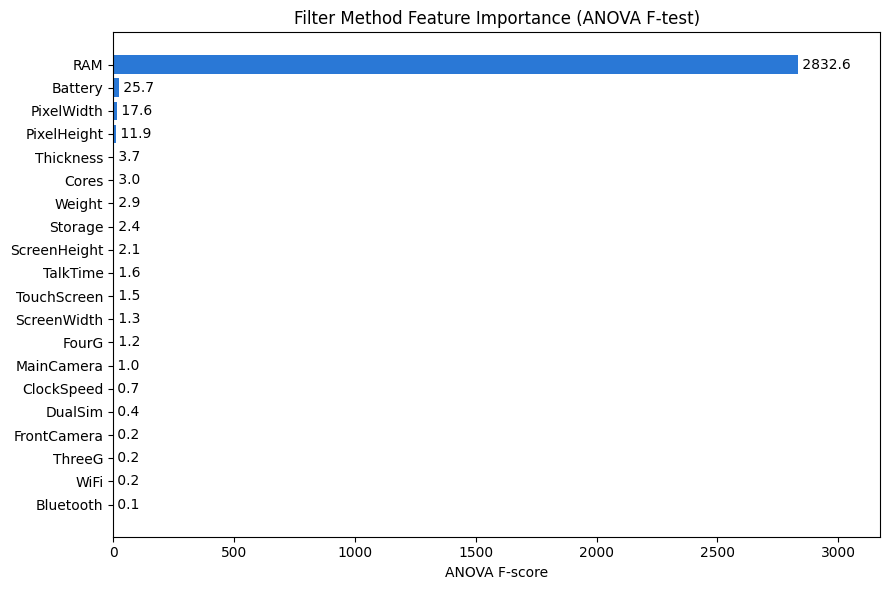

In [12]:
# put your answer here
scores_filter = pd.Series(selector_filter.scores_, index=features).sort_values()

bar_colors = [
    "#2a78d6" if f in cols_filter else "#c4c4c4" for f in scores_filter.index
]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(scores_filter.index, scores_filter.values, color=bar_colors)

for i, v in enumerate(scores_filter.values):
  ax.text(v, i, f" {v:.1f}", va="center")

ax.set_xlabel("ANOVA F-score")
ax.set_title("Filter Method Feature Importance (ANOVA F-test)")

ax.set_xlim(0, scores_filter.max() * 1.12)

plt.tight_layout()
plt.show()


# PART 2 — WRAPPER METHOD: RFECV `(25 pts)`

A wrapper method **trains the model again and again** on different subsets of features and keeps the subset with the best result.

You will use `RFECV`: it removes the weakest feature one at a time (**Recursive Feature Elimination**), checks the accuracy of every subset with **Cross-Validation**, and picks the best **number** of features by itself.

## 7. Run RFE with Cross-Validation `(8 pts)`

1. Create an `RFECV` named `rfecv` with `LogisticRegression(max_iter=1000)` as the estimator, `step=1`, `cv=StratifiedKFold(5)` and `scoring="accuracy"`. `(4 pts)`
2. Fit it on `X_train` and `y_train`, and print the best number of features. `(4 pts)`

*Hint: the best number of features is in `rfecv.n_features_`.*

In [13]:
# put your answer here

rfecv = RFECV(LogisticRegression(max_iter=1000), step=1, cv=StratifiedKFold(5), scoring="accuracy")
rfecv.fit(X_train, y_train)
print(rfecv.n_features_)

7


## 8. Select and Evaluate `(7 pts)`

1. Get the **names** of the selected features as a list and save it as `cols_wrapper`. Print it. `(3 pts)`
2. Create a `LogisticRegression(max_iter=1000)` named `model_wrapper`, train it on `X_train[cols_wrapper]`, predict `X_test[cols_wrapper]` as `pred_wrapper`, and save the accuracy as `acc_wrapper`. Print it. `(4 pts)`

*Hint: for RFECV, the True/False list is `rfecv.support_`.*

In [14]:
# put your answer here

cols_wrapper = list(X_train.columns[rfecv.support_])
model_wrapper = LogisticRegression(max_iter=1000)
model_wrapper.fit(X_train[cols_wrapper], y_train)
pred_wrapper = model_wrapper.predict(X_test[cols_wrapper])

acc_wrapper = accuracy_score(y_test, pred_wrapper)
print(acc_wrapper)

0.99


## 9. Visualize the Wrapper Method `(10 pts)`

Draw a **line chart** of the cross-validation accuracy for every number of features that RFECV tried.

1. Take `"n_features"`, `"mean_test_score"` and `"std_test_score"` from `rfecv.cv_results_` and save them as `n_feats`, `mean_acc` and `std_acc`. `(3 pts)`
2. Draw the accuracy with **error bars**. `(4 pts)`
3. Draw a **red dashed vertical line** at the best number of features, and add axis labels, a title and a legend. `(3 pts)`

*Hints:*
- *`ax.errorbar(n_feats, mean_acc, yerr=std_acc, marker="o", capsize=3, label="Mean CV accuracy")`*
- *`ax.axvline(rfecv.n_features_, color="#d1495b", linestyle="--", label=f"Best = {rfecv.n_features_} features")`*

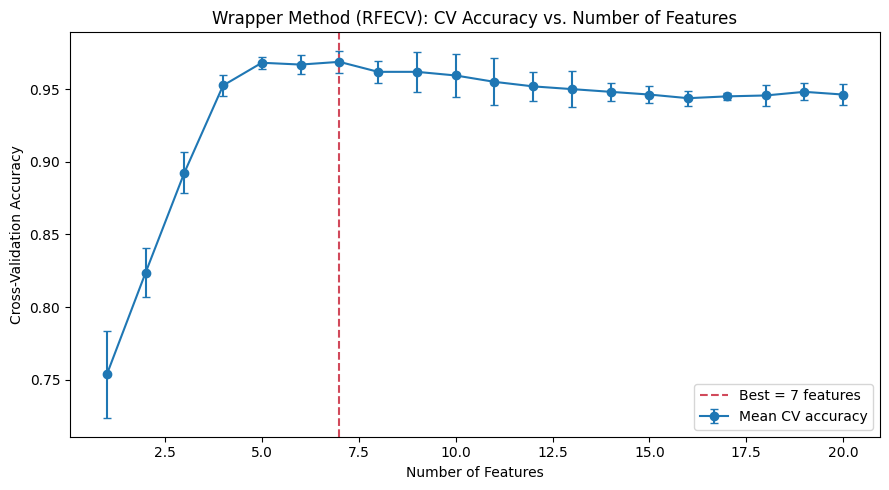

In [15]:
# put your answer here
n_feats = rfecv.cv_results_["n_features"]
mean_acc = rfecv.cv_results_["mean_test_score"]
std_acc = rfecv.cv_results_["std_test_score"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    n_feats,
    mean_acc,
    yerr=std_acc,
    marker="o",
    capsize=3,
    label="Mean CV accuracy",
)
ax.axvline(
    rfecv.n_features_,
    color="#d1495b",
    linestyle="--",
    label=f"Best = {rfecv.n_features_} features",
)

ax.set_xlabel("Number of Features")
ax.set_ylabel("Cross-Validation Accuracy")
ax.set_title("Wrapper Method (RFECV): CV Accuracy vs. Number of Features")
ax.legend()

plt.tight_layout()
plt.show()

# PART 3 — EMBEDDED METHOD: Random Forest + SelectFromModel `(25 pts)`

In an embedded method, feature selection happens **during training**: the model has its own built-in way to measure how important each feature is.

You will train a **Random Forest**, which computes a **feature importance** for every feature while it trains. Then `SelectFromModel` keeps the features with **above-average** importance.

## 10. Train the Model `(8 pts)`

1. Create a `RandomForestClassifier(n_estimators=200, random_state=42)` and name it `rf`. `(4 pts)`
2. Train it on `X_train` and `y_train`. `(4 pts)`

In [18]:
# put your answer here
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

## 11. Select and Evaluate `(7 pts)`

1. Create a `SelectFromModel` named `sfm` that uses the trained `rf`. Get the **names** of the selected features as a list, save it as `cols_embedded`, and print it. `(3 pts)`
2. Create a `LogisticRegression(max_iter=1000)` named `model_embedded`, train it on `X_train[cols_embedded]`, predict `X_test[cols_embedded]` as `pred_embedded`, and save the accuracy as `acc_embedded`. Print it. `(4 pts)`

*Hint: `SelectFromModel(rf, prefit=True)` (`prefit=True` = the model is already trained), then `sfm.get_support()`.*

In [19]:
# put your answer here
sfm = SelectFromModel(rf, prefit=True)
cols_embedded = list(X_train.columns[sfm.get_support()])
model_embedded = LogisticRegression(max_iter=1000)
model_embedded.fit(X_train[cols_embedded], y_train)
pred_embedded = model_embedded.predict(X_test[cols_embedded])

acc_embedded = accuracy_score(y_test, pred_embedded)
print(acc_embedded)

0.9675


## 12. Visualize the Embedded Method `(10 pts)`

Draw a **horizontal bar chart** of the importance of every feature.

1. Put `rf.feature_importances_` in a pandas Series with `features` as the index, sort it, and save it as `importances`. `(3 pts)`
2. Draw one bar per feature. Color the **selected** features **green** (`"#3a9d5d"`) and the others **gray** (`"#c4c4c4"`). `(4 pts)`
3. Draw the **threshold** as a red dashed vertical line, and add an x-axis label, a title and a legend. `(3 pts)`

*Hints:*
- *Same steps as Section 6, but with `importances` and `cols_embedded`.*
- *The threshold is the average importance: `threshold = importances.mean()`.*
- *`ax.axvline(threshold, color="#d1495b", linestyle="--", label="Threshold")`*

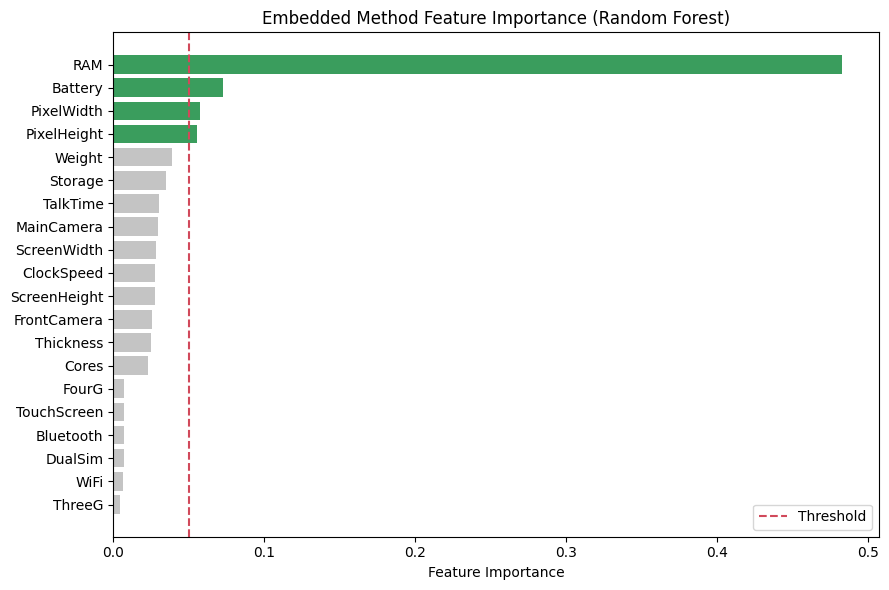

In [20]:
# put your answer here
importances = pd.Series(rf.feature_importances_, index=features).sort_values()
threshold = importances.mean()

bar_colors = [
    "#3a9d5d" if f in cols_embedded else "#c4c4c4" for f in importances.index
]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importances.index, importances.values, color=bar_colors)
ax.axvline(threshold, color="#d1495b", linestyle="--", label="Threshold")

ax.set_xlabel("Feature Importance")
ax.set_title("Embedded Method Feature Importance (Random Forest)")
ax.legend()

plt.tight_layout()
plt.show()

## 13. Compare the Methods

Run the cell below to compare the baseline with your three methods.

,Method,Type,Num Features,Selected Features,Test Accuracy
0,All features (baseline),None,20,all,0.9650
1,Filter: SelectKBest,Filter,4,"Battery, PixelHeight, PixelWidth, RAM",0.9675
2,Wrapper: RFECV,Wrapper,7,"Battery, Storage, Weight, PixelHeight, PixelWi...",0.9900
3,Embedded: Random Forest,Embedded,4,"Battery, PixelHeight, PixelWidth, RAM",0.9675


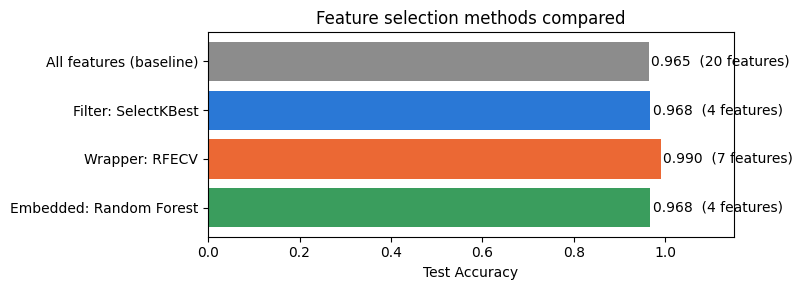

In [21]:
# Compares the baseline (all features) with the three feature selection methods
comparison = pd.DataFrame({
    "Method": ["All features (baseline)", "Filter: SelectKBest", "Wrapper: RFECV", "Embedded: Random Forest"],  # Method names
    "Type":   ["None", "Filter", "Wrapper", "Embedded"],                                                       # Method family
    "Num Features": [len(features), len(cols_filter), len(cols_wrapper), len(cols_embedded)],                  # How many features each one used
    "Selected Features": ["all", ", ".join(cols_filter), ", ".join(cols_wrapper), ", ".join(cols_embedded)],  # Which features
    "Test Accuracy": [acc_all, acc_filter, acc_wrapper, acc_embedded],                                         # Accuracy on the test set
}).round(4)                                                    # Round numbers to 4 decimals
display(comparison)                                            # Show the table

type_colors = {"None": "#8c8c8c", "Filter": "#2a78d6", "Wrapper": "#eb6834", "Embedded": "#3a9d5d"}  # One color per method type
plt.figure(figsize=(8, 3))                                                                          # Create the figure
plt.barh(comparison["Method"], comparison["Test Accuracy"], color=comparison["Type"].map(type_colors))  # One bar per method
for i, (v, n) in enumerate(zip(comparison["Test Accuracy"], comparison["Num Features"])):          # For every bar...
    plt.text(v + 0.005, i, f"{v:.3f}  ({n} features)", va="center")                                # ...write its accuracy and number of features
plt.xlim(0, 1.15)                                                                                   # Leave room for the text
plt.xlabel("Test Accuracy")                                                                         # x-axis label
plt.title("Feature selection methods compared")                                                     # Title
plt.gca().invert_yaxis()                                                                            # Baseline on top
plt.tight_layout()                                                                                  # Fit everything nicely
plt.show()                                                                                          # Display the chart